# Exploración: personas procesadas (sin sentencia)

Gráficas tempranas de README §8. Fuente: `data/processed/` (extraída de los PDF del Cuaderno
Mensual). Antes de la primera tabla por entidad extraída, el nivel nacional sale de la tabla
de 13 meses del cuaderno más reciente que reporta cada mes.

`exploracion.py` (celdas `# %%`) es la fuente versionable; `exploracion.ipynb` es su versión
ejecutada. Correr el .py directo también regenera las PNG en `graficas/`.

In [1]:
import re
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

RAIZ = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
P = RAIZ / "data/processed"
G = RAIZ / "graficas"
G.mkdir(exist_ok=True)

# paleta de referencia (dataviz): slots 1-2 validados para todo par
AZUL, NARANJA = "#2a78d6", "#eb6834"
TINTA, TINTA2, REJILLA = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": TINTA2, "axes.labelcolor": TINTA2,
                     "xtick.color": TINTA2, "ytick.color": TINTA2, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": REJILLA,
                     "grid.linewidth": 0.6, "lines.linewidth": 2, "figure.dpi": 110})

SEXENIOS = [("Zedillo", "1994-12", "2000-11"), ("Fox", "2000-12", "2006-11"), ("Calderón", "2006-12", "2012-11"), ("Peña Nieto", "2012-12", "2018-11"), ("López Obrador", "2018-12", "2024-09"),
            ("Sheinbaum", "2024-10", "2030-09")]
HITOS = [("2016-06", "SPA en todo el país"), ("2019-04", "PPO ampliada · cierre Islas Marías"),
         ("2020-04", "Ley de Amnistía"), ("2024-09", "Reforma judicial"),
         ("2024-12", "PPO ampliada"), ("2025-09", "Juzgadores electos")]


def mes(s):
    return pd.Period(s, "M").to_timestamp()


def decorar(ax, inicio, fin, etiquetas=True):
    for i, (nombre, a, b) in enumerate(SEXENIOS):
        a, b = max(mes(a), inicio), min(mes(b) + pd.offsets.MonthEnd(0), fin)
        if a >= b:
            continue
        ax.axvspan(a, b, color="#f0efec" if i % 2 else "#ffffff", zorder=0, lw=0)
        ax.text(a + (b - a) / 2, 1.01, nombre, transform=ax.get_xaxis_transform(),
                ha="center", va="bottom", color=TINTA2, fontsize=9)
    for f, t in HITOS:
        x = mes(f)
        if x >= inicio:
            ax.axvline(x, color=TINTA2, lw=0.8, ls=(0, (2, 2)), zorder=1)
            if etiquetas:
                ax.text(x, 0.02, " " + t, rotation=90, transform=ax.get_xaxis_transform(),
                        va="bottom", ha="right", fontsize=7.5, color=TINTA2)
    ax.set_xlim(inicio, fin)
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

## 1. Procesados a nivel nacional, por fuero

In [2]:
pob = pd.read_csv(P / "poblacion.csv", keep_default_na=False)
n13 = pd.concat([pd.read_csv(P / "nacional_13m_ocr.csv").assign(fuente="tabla 13 meses (OCR)"),  # 2000-01 a 2005-01
                 pd.read_csv(P / "nacional_13m.csv").assign(fuente="tabla 13 meses")])
ent = pob[pob.nivel == "entidad"]

nac = ent.groupby(["periodo", "fuero", "situacion"]).valor.sum().rename("valor").reset_index().assign(fuente="tabla por entidad")
previo = (n13[~n13.periodo_reportado.isin(nac.periodo)]
          .sort_values("periodo_cuaderno").groupby(["periodo_reportado", "fuero", "situacion"])[["valor", "fuente"]].last()
          .reset_index().rename(columns={"periodo_reportado": "periodo"}))
nac = pd.concat([previo, nac])
nac["fecha"] = nac.periodo.map(mes)
w = nac.pivot_table(index="fecha", columns=["fuero", "situacion"], values="valor")
total = w.T.groupby(level=0).sum().T  # por fuero
proc = w.xs("procesada", axis=1, level=1)
pct = proc / total * 100
ocr = nac[nac.fuente.str.contains("OCR")].fecha.max()  # último mes que sale del OCR
print("Cobertura:", w.index.min().date(), "a", w.index.max().date(), "|", len(w), "meses | OCR hasta", ocr.date())
pct.tail(3).round(1)

Cobertura: 2000-01-01 a 2026-08-01 | 320 meses | OCR hasta 2004-12-01


fuero,comun,federal
fecha,,
2026-06-01,42.4,47.9
2026-07-01,43.0,46.2
2026-08-01,43.4,48.3


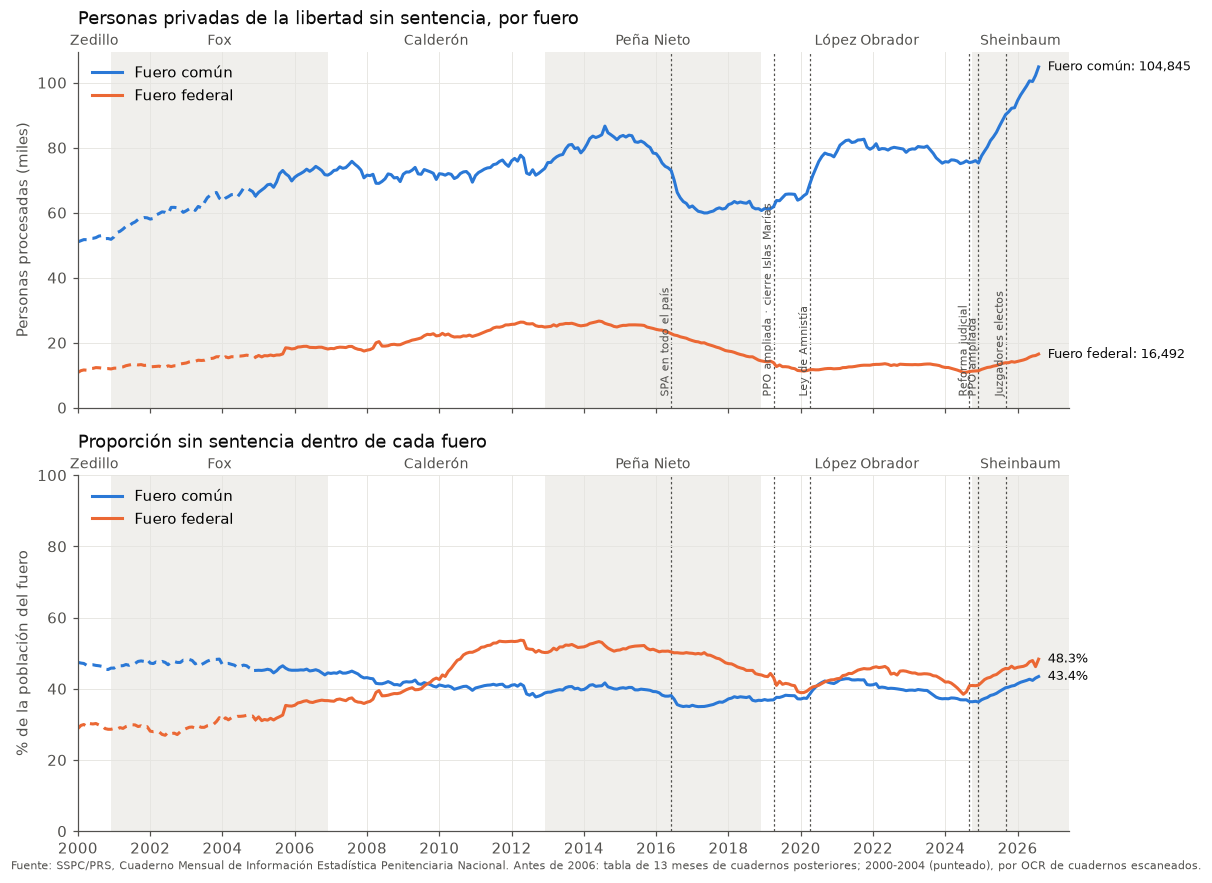

In [3]:
inicio, fin = w.index.min(), w.index.max() + pd.DateOffset(months=10)  # margen para las etiquetas finales
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
for f, c, nombre in (("comun", AZUL, "Fuero común"), ("federal", NARANJA, "Fuero federal")):
    # tramo del OCR punteado; comparte su último mes con el tramo con texto
    for a, s in ((a1, proc[f] / 1000), (a2, pct[f])):
        a.plot(s[:ocr], color=c, ls=(0, (3, 2)))
        a.plot(s[ocr:], color=c, label=nombre)
    a1.annotate(f"{nombre}: {proc[f].iloc[-1]:,.0f}", (proc.index[-1], proc[f].iloc[-1] / 1000),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=8.5, color=TINTA)
    a2.annotate(f"{pct[f].iloc[-1]:.1f}%", (pct.index[-1], pct[f].iloc[-1]),
                xytext=(6, 0), textcoords="offset points", va="center", fontsize=8.5, color=TINTA)
a1.set_ylabel("Personas procesadas (miles)")
a2.set_ylabel("% de la población del fuero")
a1.set_ylim(0)
a2.set_ylim(0, 100)
for a, etiquetas in ((a1, True), (a2, False)):
    decorar(a, inicio, fin, etiquetas)
    a.legend(loc="upper left", frameon=False)
a1.set_title("Personas privadas de la libertad sin sentencia, por fuero", loc="left", color=TINTA, pad=18)
a2.set_title("Proporción sin sentencia dentro de cada fuero", loc="left", color=TINTA, pad=18)
fig.text(0.01, 0.005, "Fuente: SSPC/PRS, Cuaderno Mensual de Información Estadística Penitenciaria Nacional. "
         "Antes de 2006: tabla de 13 meses de cuadernos posteriores; 2000-2004 (punteado), por OCR de cuadernos escaneados.",
         fontsize=7.5, color=TINTA2)
fig.tight_layout()
fig.savefig(G / "1_procesados_nacional.png", bbox_inches="tight")

## 2. % de procesados por entidad (ambos fueros)

Los centros federales van como su propia "entidad". Nombres de entidad unificados solo para
la gráfica (la base guarda la grafía original en `entidad_raw`).

entidad
San Luis Potosi    85.0
Quintana Roo       74.5
Veracruz           64.7
Sonora             60.5
Jalisco            60.2
Tlaxcala           59.7
Nayarit            59.2
Coahuila           57.9
Baja California    55.9
Oaxaca             52.9
Name: 2026-08-01 00:00:00, dtype: float64

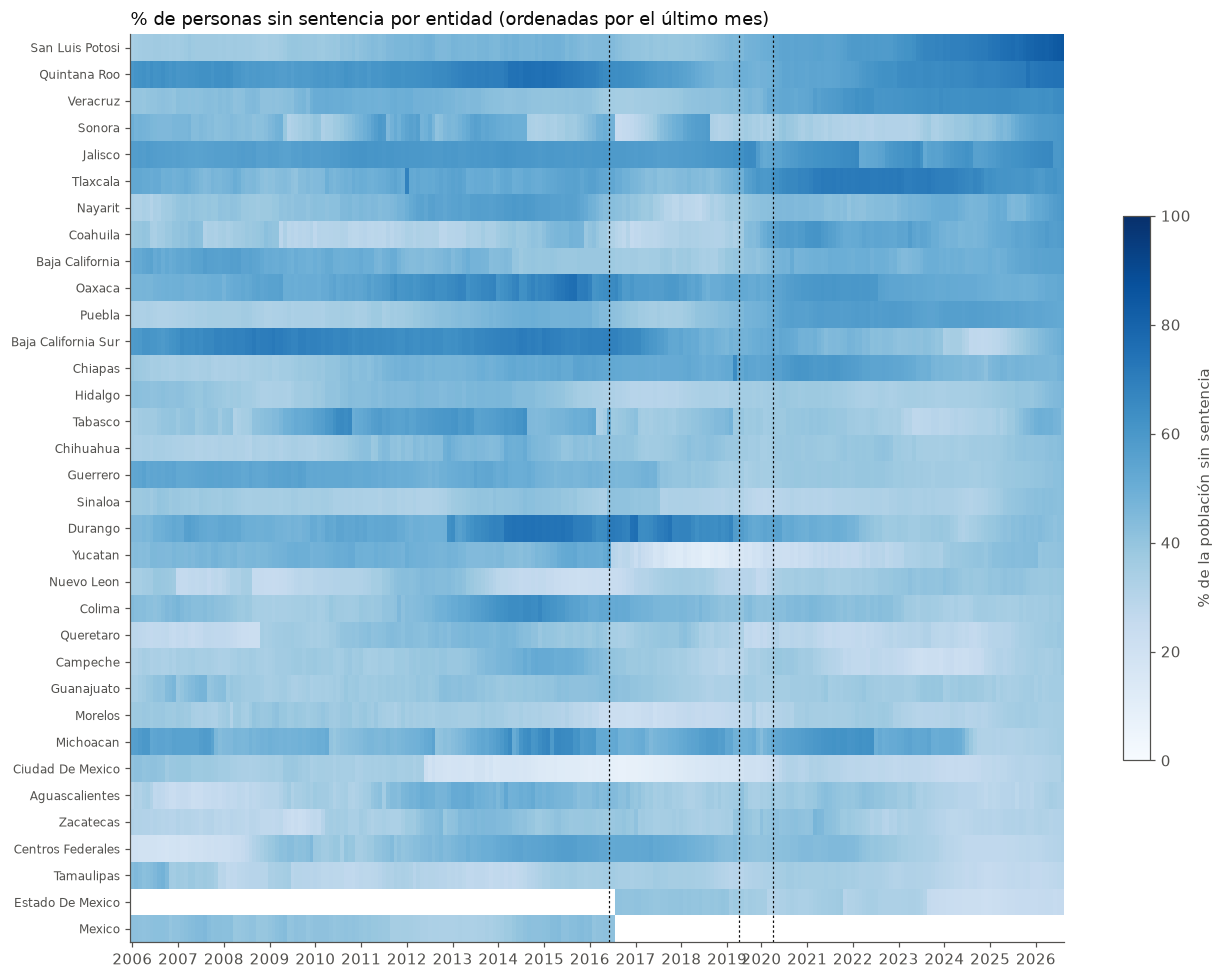

In [4]:
def clave(s):
    s = unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode().upper()
    s = re.sub(r"[^A-Z ]", " ", s)
    for largo, corto in (("COAHUILA DE ZARAGOZA", "COAHUILA"), ("MICHOACAN DE OCAMPO", "MICHOACAN"),
                         ("VERACRUZ DE IGNACIO DE LA LLAVE", "VERACRUZ"), ("VERACRUZ DE IGNACIO DE LA", "VERACRUZ"),
                         ("DISTRITO FEDERAL", "CIUDAD DE MEXICO")):
        s = s.replace(largo, corto)
    return " ".join(s.split()).title()


e2 = ent.assign(entidad=ent.entidad_raw.map(clave), fecha=ent.periodo.map(mes))
t = e2.pivot_table(index="entidad", columns="fecha", values="valor", aggfunc="sum")
p = e2[e2.situacion == "procesada"].pivot_table(index="entidad", columns="fecha", values="valor", aggfunc="sum")
hm = (p / t * 100).sort_values(t.columns.max(), ascending=False)

fig, ax = plt.subplots(figsize=(12, 9))
im = ax.imshow(hm.values, aspect="auto", cmap="Blues", vmin=0, vmax=100, interpolation="nearest")
ax.set_yticks(range(len(hm)), hm.index, fontsize=8)
anios = [i for i, c in enumerate(hm.columns) if c.month == 1]
ax.set_xticks(anios, [hm.columns[i].year for i in anios])
ax.grid(False)
for f, _ in HITOS[:3]:
    if mes(f) in hm.columns:
        ax.axvline(list(hm.columns).index(mes(f)), color=TINTA, lw=0.8, ls=(0, (2, 2)))
fig.colorbar(im, ax=ax, label="% de la población sin sentencia", shrink=0.6)
ax.set_title("% de personas sin sentencia por entidad (ordenadas por el último mes)", loc="left", color=TINTA)
fig.tight_layout()
fig.savefig(G / "2_procesados_entidad.png", bbox_inches="tight")
hm.iloc[:, -1].round(1).head(10)

## 3. Centros federales: procesados por centro

Nombres sin armonizar en la base; aquí se agrupan solo por número de CEFERESO para la gráfica.

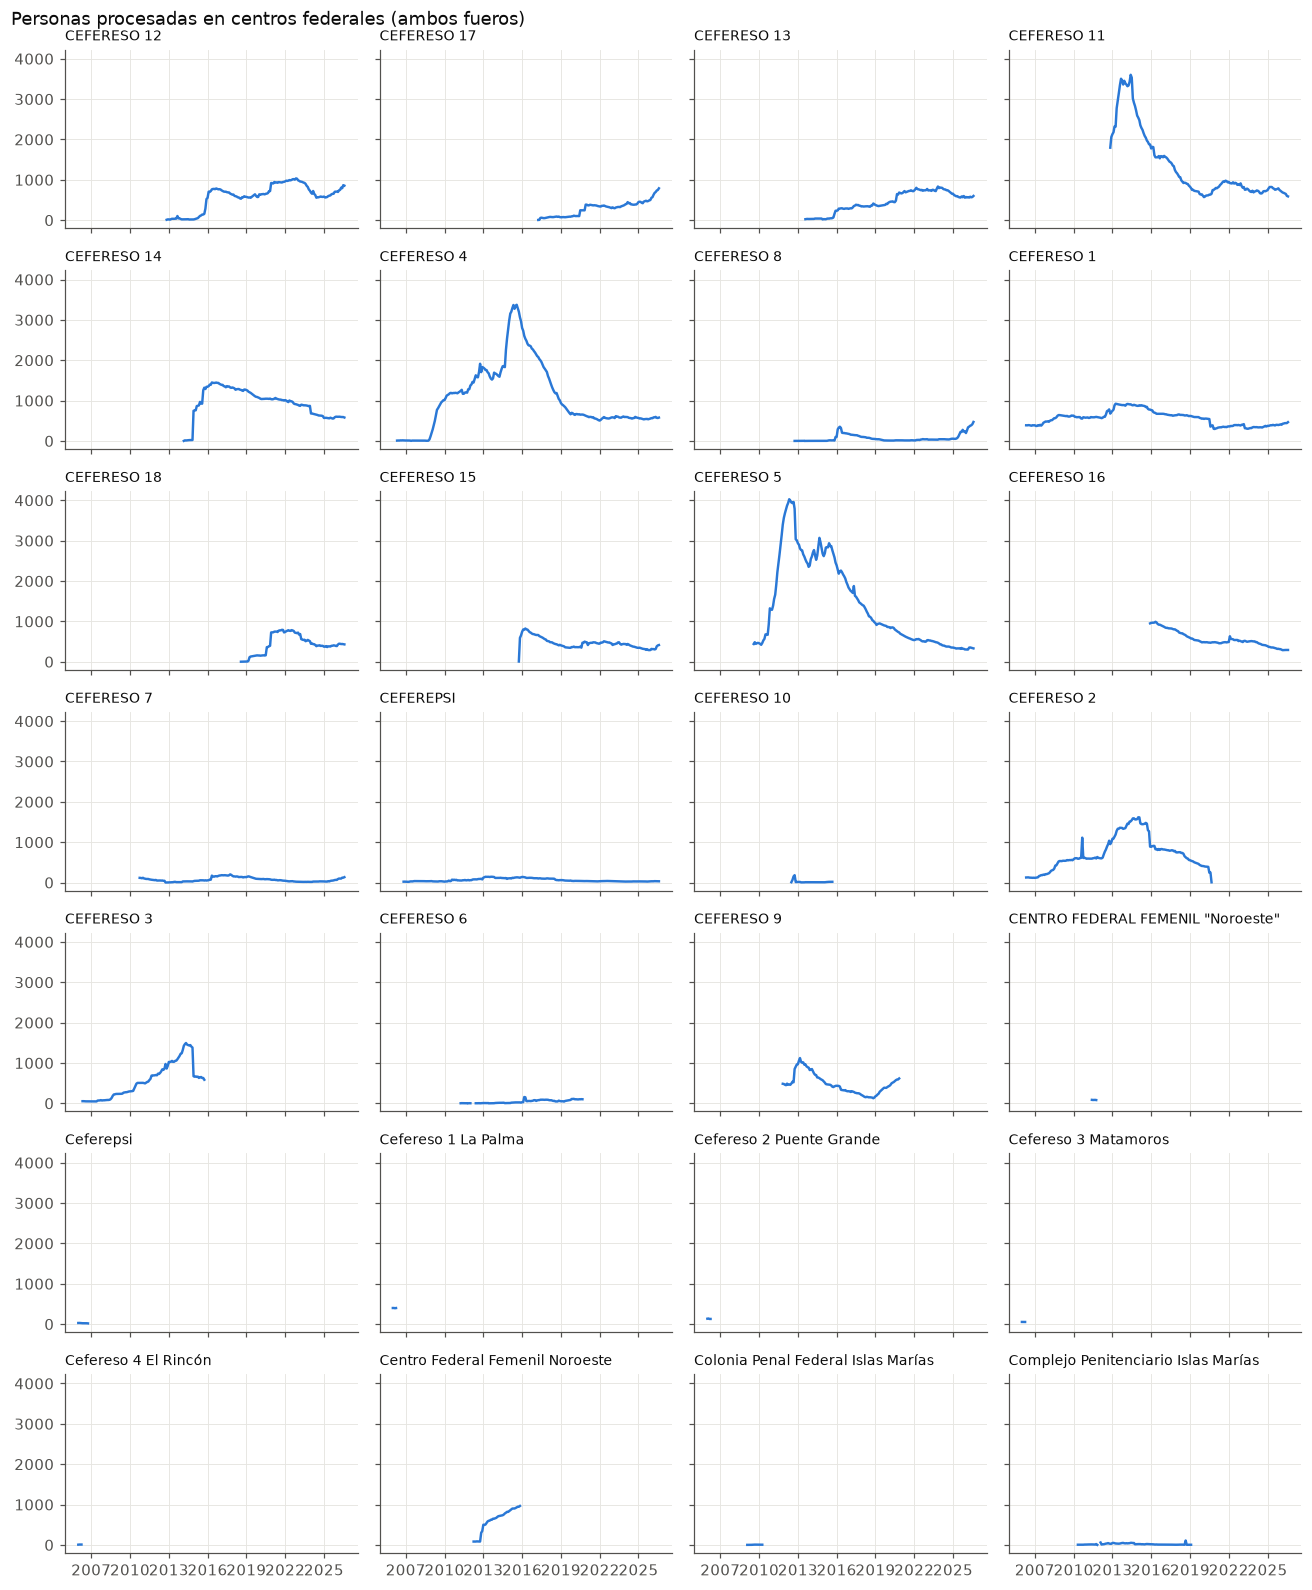

In [5]:
fed = ent[ent.ambito_centro == "federal"].copy()
num = fed.centro_raw.str.extract(r"(?:No\.?|Federal)\s*(\d+)")[0]
# algunos nombres traen letras espaciadas de un texto vertical vecino ("C o a h u i l a CEFEREPSI")
fed["centro"] = ("CEFERESO " + num.fillna("")).where(num.notna(), fed.centro_raw.str.replace(r"^(\w )+", "", regex=True).str.strip())
fed["fecha"] = fed.periodo.map(mes)
cf = fed[fed.situacion == "procesada"].pivot_table(index="fecha", columns="centro", values="valor", aggfunc="sum")
cf = cf[cf.iloc[-1].sort_values(ascending=False, na_position="last").index]  # vigentes primero
cols = 4
filas = -(-len(cf.columns) // cols)
fig, axs = plt.subplots(filas, cols, figsize=(12, 2.1 * filas), sharex=True, sharey=True)
for ax, c in zip(axs.flat, cf.columns):
    ax.plot(cf.index, cf[c], color=AZUL, lw=1.6)
    ax.set_title(c, loc="left", fontsize=9, color=TINTA)
    ax.xaxis.set_major_locator(mdates.YearLocator(3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
for ax in list(axs.flat)[len(cf.columns):]:
    ax.set_visible(False)
fig.suptitle("Personas procesadas en centros federales (ambos fueros)", x=0.01, ha="left", color=TINTA)
fig.tight_layout()
fig.savefig(G / "3_procesados_ceferesos.png", bbox_inches="tight")